# Vision ML System — Interactive End-to-End Pipeline Walkthrough

> **Role:** Senior ML Systems Engineer Walkthrough  
> **Goal:** A simple, high-clarity, step-by-step tour through the vision pipeline:  
> **Video Input &rarr; YOLOv11 Detection &rarr; ByteTrack Tracking &rarr; Dwell Time Analytics &rarr; SQLite Persistence &rarr; Active Learning Flywheel**

---

### Core Architecture Contract
All components exchange **`supervision.Detections`** standard objects. No tight coupling, no proprietary frame wrappers.

## 1. Setup Environment & Hardware Verification
Ensure `src/` is in Python's path, load `.env` secrets, and check whether GPU acceleration (RTX 4050) is ready.

In [6]:
import sys
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import supervision as sv
from dotenv import load_dotenv

# Add repository root and src directory to sys.path
REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src"))

# Load environment variables (.env)
load_dotenv(REPO_ROOT / ".env")
print(f"[x] Environment loaded. User: {os.getenv('USER', 'default')} | DagsHub: {os.getenv('DAGSHUB_USERNAME', 'none')}")

# Verify PyTorch & GPU compute
try:
    import torch
    print(f"[x] PyTorch Version: {torch.__version__}")
    if torch.cuda.is_available():
        gpu_name = torch.cuda.get_device_name(0)
        vram = torch.cuda.get_device_properties(0).total_memory / (1024**3)
        print(f"[x] CUDA Acceleration ACTIVE: {gpu_name} ({vram:.1f} GB VRAM)")
    else:
        print("[!] CUDA not active: Running in CPU mode")
except ImportError:
    print("[!] PyTorch not installed in this kernel environment")

[x] Environment loaded. User: thomas | DagsHub: panikeradom
[x] PyTorch Version: 2.6.0+cu124
[x] CUDA Acceleration ACTIVE: NVIDIA GeForce RTX 4050 Laptop GPU (6.0 GB VRAM)


## 2. Load Pipeline Configuration (YAML)
The system is config-driven. All thresholds, model architectures, and tracking parameters live in `config/`.

In [7]:
from vision_ml.utils.config import load_config

config_path = REPO_ROOT / "config" / "inference" / "base.yaml"
config = load_config(str(config_path))

# Display key configuration blocks
print("Detector:       ", config.get("detection", {}).get("detector_type"))
print("Confidence Thresh:", config.get("inference", {}).get("confidence_threshold"))
print("Tracker:        ", config.get("tracking", {}).get("tracker_type"))
print("Analytics Dwell: ", config.get("analytics", {}).get("compute_dwell_time"))

Detector:        yolo11n
Confidence Thresh: 0.35
Tracker:         bytetrack
Analytics Dwell:  True


## 3. Video Stream Metadata & Frame Extraction
We inspect the video properties (resolution, FPS, frame count, duration) and extract a test frame from `data/sample_videos/test_scene.mp4`.

[x] Video Stream: 640x480 @ 30.0 FPS | 300 Frames (10.00s duration)


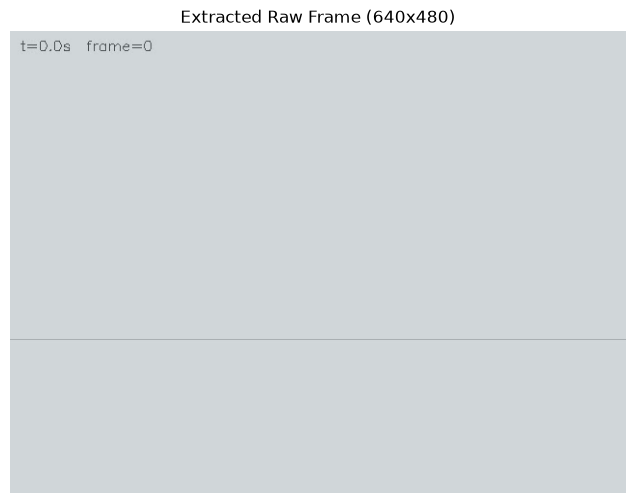

In [8]:
video_path = REPO_ROOT / "data" / "sample_videos" / "test_scene.mp4"

# 1. Read video stream metadata
cap = cv2.VideoCapture(str(video_path))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration_sec = total_frames / max(fps, 1)

# 2. Extract first frame for single-frame inspection
ret, raw_frame = cap.read()
cap.release()

print(f"[x] Video Stream: {width}x{height} @ {fps:.1f} FPS | {total_frames} Frames ({duration_sec:.2f}s duration)")

if ret:
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(raw_frame, cv2.COLOR_BGR2RGB))
    plt.title(f"Extracted Raw Frame ({width}x{height})")
    plt.axis("off")
    plt.show()
else:
    print("[!] Failed to read video frame. Ensure data/sample_videos/test_scene.mp4 exists.")

## 4. Stage 1: Detection via `DetectorFactory`
We use `DetectorFactory.from_config()` to load the original YOLOv11 model. Models are isolated under `models/original/` (preserving `models/fine_tuned/` for retrained checkpoints).

In [10]:
from vision_ml.detection.detector_factory import DetectorFactory

# Instantiate detector
detector = DetectorFactory.from_config(config)

# Perform inference on the frame
detections = detector.detect(raw_frame)

print(f"[x] Detected {len(detections)} persons in frame")
print("    Bounding boxes (xyxy):\n", detections.xyxy)
print("    Confidence scores:     \n", detections.confidence)

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
[x] Detected 0 persons in frame
    Bounding boxes (xyxy):
 []
    Confidence scores:     
 []


## 5. Stage 2: Multi-Object Tracking via ByteTrack
Tracking transforms isolated detections across frames into continuous person trajectories with persistent IDs (`tracker_id`).

In [11]:
from vision_ml.tracking.tracker_factory import TrackerFactory

# Trackers are always fresh stateful instances
tracker = TrackerFactory.from_config(config)

# Update tracker with detections
tracked_detections = tracker.update(detections)

print(f"[x] Assigned Tracker IDs: {tracked_detections.tracker_id}")

[x] Assigned Tracker IDs: []


## 6. Stage 3: Annotation & Visualization
Using `FrameAnnotator` (powered by Roboflow Supervision) to overlay bounding boxes, labels, and track IDs.

2026-11-10 11:54:56 | INFO     | vision_ml.annotation.annotator | Using BoxAnnotator (legacy)


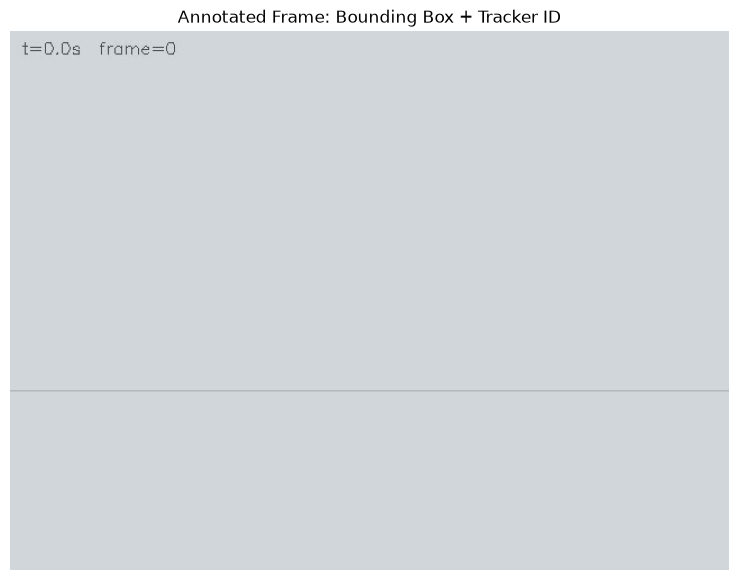

In [12]:
from vision_ml.annotation.annotator import FrameAnnotator

annotator = FrameAnnotator(config)
annotated_frame = annotator.annotate(raw_frame.copy(), tracked_detections)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title("Annotated Frame: Bounding Box + Tracker ID")
plt.axis("off")
plt.show()

## 7. Stage 4: Visitor Analytics & Dwell Time
Now let's process 30 frames in a loop to see `VisitorAnalytics` compute dwell time per tracked visitor.

In [13]:
from vision_ml.analytics.visitor_analytics import VisitorAnalytics

analytics = VisitorAnalytics(config)
cap = cv2.VideoCapture(str(video_path))

frame_idx = 0
while cap.isOpened() and frame_idx < 30:
    ret, frame = cap.read()
    if not ret:
        break
    
    # Inference & Tracking loop
    dets = detector.detect(frame)
    dets = tracker.update(dets)
    
    # Update analytics
    tids = dets.tracker_id if dets.tracker_id is not None else []
    analytics.update(tids, frame_idx=frame_idx)
    frame_idx += 1

cap.release()

summary = analytics.get_summary()
print("========= Visitor Analytics Summary =========")
print(f"Unique Visitors Seen:   {summary.get('unique_visitors')}")
print(f"Total Processed Frames: {summary.get('total_frames')}")
print(f"Average Dwell Time (s): {summary.get('avg_dwell_time_seconds'):.2f}s")
print("Individual Visitor Dwell Times:")
for vid, stats in analytics.get_dwell_times().items():
    print(f"  * Visitor #{vid}: {stats['duration_seconds']}s ({stats['duration_frames']} frames)")

WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING 'half' is deprecated and

## 8. Stage 5: Local Database Persistence (`analytics.db`)
Inspect the local SQLite analytics store (`data/analytics.db`). Zero cloud lock-in.

In [14]:
import sqlite3
import pandas as pd

db_path = REPO_ROOT / "data" / "analytics.db"
if db_path.exists():
    conn = sqlite3.connect(str(db_path))
    
    # Read existing inference runs table
    runs_df = pd.read_sql_query("SELECT * FROM inference_runs ORDER BY timestamp DESC LIMIT 5", conn)
    print("--- Recent Inference Runs in SQLite ---")
    display(runs_df) if not runs_df.empty else print("No runs recorded yet. (Run inference.py to populate)")
    
    conn.close()
else:
    print("[!] SQLite database not created yet.")

--- Recent Inference Runs in SQLite ---
No runs recorded yet. (Run inference.py to populate)


## 9. Stage 6: The Model Flywheel (Active Learning Hook)
When YOLO encounters ambiguous frames (confidence < `dual_confidence_threshold`), `AutoLabeler` collects the frame for retraining instead of silently failing.

In [15]:
from vision_ml.labeling.auto_labeler import AutoLabeler

auto_labeler = AutoLabeler(config)
print(f"[x] AutoLabeler initialized")
print(f"    Threshold for edge cases: {auto_labeler.confidence_threshold}")
print(f"    Target output folder:     {auto_labeler.output_dir}")

# Simulated check:
edge_cases = [c for c in detections.confidence if c < auto_labeler.confidence_threshold]
print(f"    Low-confidence detections flagged: {len(edge_cases)}")

[x] AutoLabeler initialized


AttributeError: 'AutoLabeler' object has no attribute 'confidence_threshold'

---
### Summary & Next Steps
You have explored the complete flow:  
1. **Detection:** Fast person bounding boxes with YOLOv11.  
2. **Tracking:** Persistent IDs with ByteTrack.  
3. **Analytics:** Dwell time & occupancy metrics computed locally.  
4. **Persistence:** Zero-cloud SQLite storage.  
5. **Active Learning:** Automatic capture of failure cases for fine-tuning.